## KNN classifier

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, recall_score, make_scorer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('breast_cancer.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
# removing the unnecessary columns
df = df.drop(columns=['id','Unnamed: 32'])
df.columns

Index(['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [5]:
cols = df.columns.to_list()
cols

['diagnosis',
 'radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

In [6]:
cols = cols[1:]
cols

['radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

In [7]:
# scaling pipepline
feature_cols = cols 

x = df[feature_cols]
y = df['diagnosis']

In [8]:
# split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
# pipeline
scaling_pipeline = Pipeline(
    steps=[
        ('scale',StandardScaler())
    ]
)

In [10]:
# preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('scaled_pipeline',scaling_pipeline,cols)
    ]
)
preprocessor

ColumnTransformer(transformers=[('scaled_pipeline',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['radius_mean', 'texture_mean',
                                  'perimeter_mean', 'area_mean',
                                  'smoothness_mean', 'compactness_mean',
                                  'concavity_mean', 'concave points_mean',
                                  'symmetry_mean', 'fractal_dimension_mean',
                                  'radius_se', 'texture_se', 'perimeter_se',
                                  'area_se', 'smoothness_se', 'compactness_se',
                                  'concavity_se', 'concave points_se',
                                  'symmetry_se', 'fractal_dimension_se',
                                  'radius_worst', 'texture_worst',
                                  'perimeter_worst', 'area_worst',
                                  'smoothness_worst', 'compactness_worst',
                                  'concavity_worst', 'concave points_worst',
                                  'symmetry_worst',
                                  'fractal_dimension_worst'])])

In [11]:
# model
model = Pipeline(steps=[
    ('preprocess',preprocessor),
    ('classify',KNeighborsClassifier())
])


# hyperparameter tuning
param_grid = [
    {
        "classify__n_neighbors": list(range(3, 32, 2)),
        "classify__weights": ["uniform", "distance"],
        "classify__metric": ["euclidean", "manhattan"],
    },
    {
        "classify__n_neighbors": list(range(3, 32, 2)),
        "classify__weights": ["uniform", "distance"],
        "classify__metric": ["minkowski"],
        "classify__p": [1, 2, 3],
    }
]

recall_m = make_scorer(recall_score, pos_label='M')

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv = 5,
    scoring=recall_m,
    n_jobs=-1
)

grid.fit(x_train, y_train)
print('best model:',grid.best_estimator_)
print('best params:',grid.best_params_)
print('best score(recall CV):',grid.best_score_)

best model: Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scaled_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['radius_mean',
                                                   'texture_mean',
                                                   'perimeter_mean',
                                                   'area_mean',
                                                   'smoothness_mean',
                                                   'compactness_mean',
                                                   'concavity_mean',
                                                   'concave points_mean',
                                                   'symmetry_mean',
                                                   'fractal_dimension_mean',
                             

                    Feature  Importance_Mean  Importance_Std
6            concavity_mean         0.025581        0.016279
26          concavity_worst         0.018605        0.009302
25        compactness_worst         0.018605        0.009302
23               area_worst         0.018605        0.017403
22          perimeter_worst         0.018605        0.017403
20             radius_worst         0.018605        0.017403
27     concave points_worst         0.016279        0.010657
3                 area_mean         0.013953        0.011393
29  fractal_dimension_worst         0.011628        0.015600
17        concave points_se         0.011628        0.011628


/var/folders/c9/p4s2n3nx6zxffbhgf6dtds_h0000gn/T/ipykernel_5207/1351344292.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


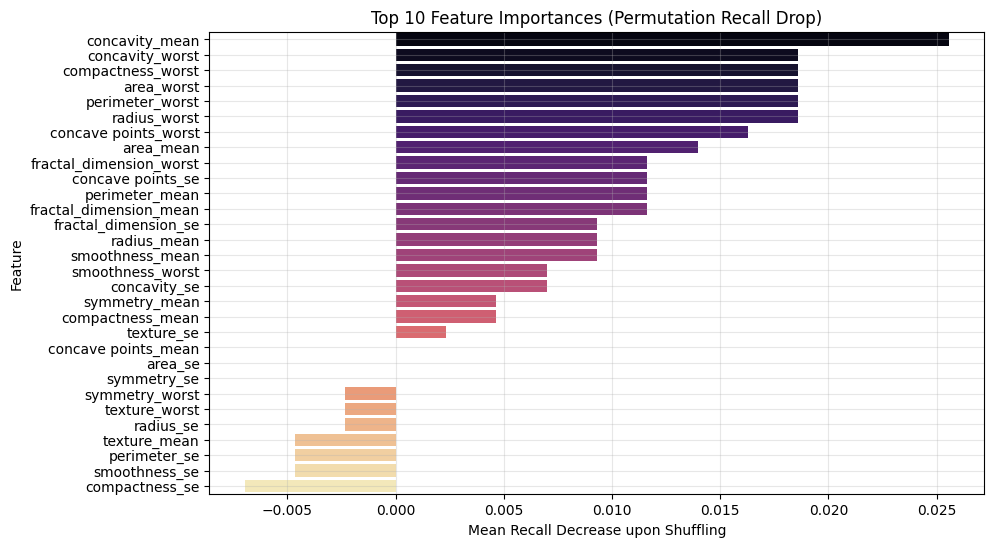

In [26]:
from sklearn.inspection import permutation_importance

# 1. Compute permutation importance
# Using recall with pos_label='M' since your target is ['B', 'M']
result = permutation_importance(
    best_model, 
    x_test, 
    y_test, 
    scoring=recall_m,     # or 'roc_auc'
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

# 2. Store results in a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

# 3. View top 10 most important features
print(importance_df.head(10))

# 4. Plot top 10 features
plt.figure(figsize=(10, 6))
top_10 = importance_df
sns.barplot(
    x='Importance_Mean', 
    y='Feature', 
    data=top_10,
    palette='magma'
)
plt.title('Top 10 Feature Importances (Permutation Recall Drop)')
plt.xlabel('Mean Recall Decrease upon Shuffling')
plt.ylabel('Feature')
plt.grid(True, alpha=0.3)
plt.show()

accuracy score:  0.9649122807017544
recall score:  0.9534883720930233


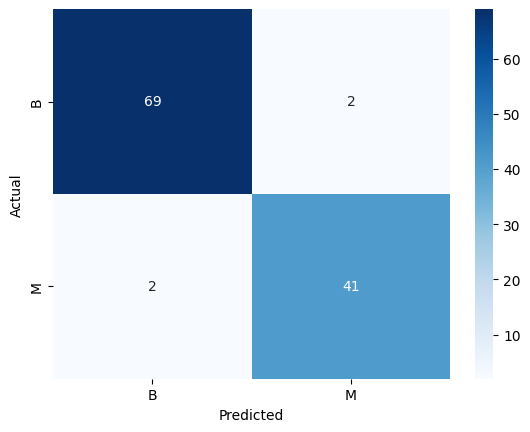

In [12]:
# model eval
best_model = grid.best_estimator_
y_Pred = best_model.predict(x_test)
print("accuracy score: ", accuracy_score(y_test, y_Pred))
print("recall score: ", recall_score(y_test, y_Pred, pos_label="M"))

cm = confusion_matrix(y_test, y_Pred, labels=["B", "M"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["B", "M"], yticklabels=["B", "M"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


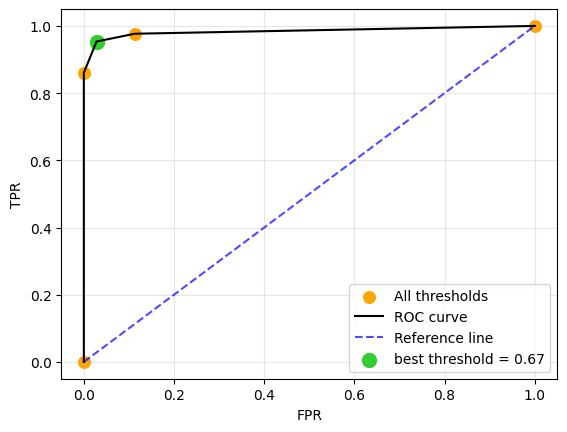


roc_auc_score:  0.9841139862430397


In [28]:
# ROC curve
y_Score = best_model.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_Score, pos_label="M")

# optimal threshold
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

# plot
plt.scatter(fpr, tpr, color = "orange", s = 70, label = "All thresholds")
plt.plot(fpr, tpr, color = "k", label = "ROC curve")
plt.plot([0,1], [0,1], color = "blue", alpha = 0.7, label = "Reference line", ls = 'dashed')
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], s = 100, color = "limegreen", label = f"best threshold = {optimal_threshold:.2f}")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

print()
print('roc_auc_score: ',roc_auc_score(y_test, y_score=y_Score))
